# Section 5: the subgame perfect gradient method on the problems of Figure 1.2

Same three problems, data, $f_\star$ and baselines (GD, HBM and NAG with the parameters of Figure 1.2) as in `Section1_experiments.ipynb`, with the subgame perfect gradient method of Section 5.4 on top. The last part adds OGM, ITEM and the triple momentum method with quadratic averaging, and puts them on the same figure as the two methods with memory of `Section4_experiments.ipynb`. Everything is in this notebook.

- **SPGM** (Algorithm 5.4, (5.21)): OGM (5.10) in which, after each query, the weight is raised to the largest value certified by the history, problem (5.19). The upper side is the best value $U_{k+1}=\min_{0\leq i\leq k}\{f(y_i)-\tfrac1{2L}\|\nabla f(y_i)\|^2\}$, attained at the gradient step $\tilde x_{k+1}$; the lower side is the maximum of the pieces $q_i$ (5.15), which are lower bounds on $f_\star$ at the minimizers. It does not use $m$, so it runs on the three problems (on (i) and (ii), NAG uses $m$).

**What is plotted.** For SPGM, $f(\tilde x_k)-f_\star$, where $\tilde x_k$ is the current upper point of the method, which satisfies $f(\tilde x_k)-f_\star\leq U_k-f_\star\leq L\|x_0-x_\star\|^2/(2\tilde A_k)$. The output of Algorithm 5.4, with its last step, improves the guarantee to $L\|x_0-x_\star\|^2/(2(\tilde A_N+\tilde a_N))$ for a horizon $N$ fixed in advance; it is not used here, since all $k$ are plotted.

**Limited memory.** The number of pieces grows with $k$. As at the end of Section 5.4, we keep the last `memory = 10` pieces together with one *aggregate* piece $\sum_i\lambda^\star_iq_i$, the average of the pieces with the optimal weights of the last subproblem. It has the same regularized minimizer and minimal value as the model it replaces, so the a priori weight of OGM remains certified at the next iteration and the realized weights satisfy $\tilde A_k\geq A_k$ (OGM's).

**Cost per iteration.** One gradient and one function value at $y_k$, and a few quadratic programs over the simplex with at most `memory + 2` variables. (The values $f(\tilde x_k)$ are only computed for the plot.)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit, logsumexp, softmax
from sklearn.datasets import load_diabetes

# Sonar data (UCI). Replace by the path of a local copy if you are offline.
SONAR_FILE = "https://archive.ics.uci.edu/ml/machine-learning-databases/undocumented/connectionist-bench/sonar/sonar.all-data"

## The three methods of Section 1

- GD (1.2): $x_{k+1} = x_k - \alpha\nabla f(x_k)$.
- HBM (1.3): $x_{k+1} = x_k - \alpha\nabla f(x_k) + \beta(x_k - x_{k-1})$, with $x_{-1} = x_0$.
- NAG (1.4): $x_{k+1} = y_k - \alpha\nabla f(y_k)$, $\ y_{k+1} = x_{k+1} + \beta_k(x_{k+1} - x_k)$, with $y_0 = x_0$.

Each function returns the values $f(x_0), f(x_1), \dots, f(x_N)$.

In [2]:
def gd(f, grad, x0, alpha, n_iter):
    x = x0.copy()
    values = [f(x)]
    for k in range(n_iter):
        x = x - alpha * grad(x)
        values.append(f(x))
    return np.array(values)


def hbm(f, grad, x0, alpha, beta, n_iter):
    x, x_prev = x0.copy(), x0.copy()
    values = [f(x)]
    for k in range(n_iter):
        x, x_prev = x - alpha * grad(x) + beta * (x - x_prev), x
        values.append(f(x))
    return np.array(values)


def nag(f, grad, x0, alpha, beta, n_iter):
    # beta is either a number or a function k -> beta_k
    x, y = x0.copy(), x0.copy()
    values = [f(x)]
    for k in range(n_iter):
        x_next = y - alpha * grad(y)
        beta_k = beta(k) if callable(beta) else beta
        y = x_next + beta_k * (x_next - x)
        x = x_next
        values.append(f(x))
    return np.array(values)


def run_methods(f, grad, x0, L, m, n_iter):
    # Parameters of the figure (see the table above).
    if m > 0:
        rL, rm = np.sqrt(L), np.sqrt(m)
        hbm_alpha, hbm_beta = 4 / (rL + rm) ** 2, ((rL - rm) / (rL + rm)) ** 2
        nag_beta = (rL - rm) / (rL + rm)
    else:
        hbm_alpha, hbm_beta = 1 / L, 0.9
        nag_beta = lambda k: k / (k + 3)
    return {
        "GD": gd(f, grad, x0, 1 / L, n_iter),
        "HBM": hbm(f, grad, x0, hbm_alpha, hbm_beta, n_iter),
        "NAG": nag(f, grad, x0, 1 / L, nag_beta, n_iter),
    }

## The subgame perfect gradient method

**The weight.** Problem (5.19) is the convex program (5.20) in $\tilde a=A\lambda$. By the display that precedes (5.20), it is also the largest $A$ such that
$$\max_{\lambda\in\Delta}\Big\{\textstyle\sum_i\lambda_i\big(q_i(x_0)-U_{k+1}\big)-\tfrac{A}{2L}\big\|\sum_i\lambda_i\nabla f(y_i)\big\|^2\Big\}\geq0,$$
and $\tilde z_{k+1}=x_0-\tfrac{\tilde A_{k+1}}L\sum_i\lambda_i^\star\nabla f(y_i)$. We solve it as for the gradient methods with memory of Section 4.5: for fixed $\lambda$, the largest certified weight is explicit,
$$A(\lambda)=\frac{2L\sum_i\lambda_i\big(q_i(x_0)-U_{k+1}\big)}{\|\sum_i\lambda_i\nabla f(y_i)\|^2},$$
and Newton's method alternates $\lambda\leftarrow$ a maximizer of the quadratic program over the simplex at the current weight (SLSQP, the problems are tiny) and $A\leftarrow A(\lambda)$. It starts from the a priori weights ($\tilde A_k/A_{k+1}$ on the aggregate piece, $a_k/A_{k+1}$ on the new one), which certify OGM's weight $A_{k+1}=\tilde A_k+a_k$, and the weights increase monotonically. Every pair $(\lambda,A(\lambda))$ is itself a certificate, so the quadratic programs need not be solved exactly.

In [3]:
def simplex_qp(b, G, t, lam):
    # A maximizer of b @ lam - t/2 ||G @ lam||^2 over the simplex, warm-started at lam.
    if len(b) == 1:
        return np.ones(1)
    s = max(t * np.max(np.sum(G ** 2, axis=0)), np.max(np.abs(b)), 1e-300)    # scale of the objective
    res = minimize(lambda l: (t / 2 * np.sum((G @ l) ** 2) - b @ l) / s, lam,
                   jac=lambda l: (t * G.T @ (G @ l) - b) / s, method="SLSQP", bounds=[(0, 1)] * len(b),
                   constraints={"type": "eq", "fun": lambda l: np.sum(l) - 1, "jac": lambda l: np.ones_like(l)},
                   options={"ftol": 1e-15, "maxiter": 200})
    lam = np.maximum(res.x, 0)
    return lam / lam.sum()


def largest_weight(b, G, L, lam, n_newton=10):
    # Problem (5.19) by Newton's method from the weights lam, with b_i = q_i(x_0) - U and G = [grad f(y_i)]:
    # largest A such that max_lam {b @ lam - A/(2L) ||G @ lam||^2} >= 0.
    certified = lambda l: 2 * L * (b @ l) / np.sum((G @ l) ** 2)     # largest weight certified by the weights l
    A = certified(lam)
    for _ in range(n_newton):
        lam_new = simplex_qp(b, G, A / L, lam)
        A_new = certified(lam_new)
        if not A_new > A * (1 + 1e-9):
            break
        A, lam = A_new, lam_new
    return A, lam


def spgm(f, grad, x0, L, n_iter, memory=10):
    # SPGM (Algorithm 5.4). Pieces q_i (5.15) stored as (q_i(x_0), grad f(y_i)); column 0 is the aggregate piece.
    # Returns f(x~_0), ..., f(x~_N) and the realized weights.
    x_tilde, z, A, U = x0.copy(), x0.copy(), 0.0, np.inf
    c, G = np.zeros(0), np.zeros((len(x0), 0))
    f_x_tilde = f(x0)
    values, weights = [f_x_tilde], [A]
    for k in range(n_iter):
        a = 1 + np.sqrt(1 + 2 * A)
        A_next = A + a                                                   # a priori weight (OGM)
        y = A / A_next * x_tilde + a / A_next * z
        g, f_y = grad(y), f(y)
        x = y - g / L
        if f_y - g @ g / (2 * L) < U:                                    # best upper bound U_{k+1}, attained at x~_{k+1}
            U, x_tilde = f_y - g @ g / (2 * L), x
            f_x_tilde = f(x_tilde)                                       # only for the plot
        c = np.append(c, f_y + g @ (x0 - y) + g @ g / (2 * L))           # new piece q_k
        G = np.column_stack([G, g])
        lam_prior = np.zeros(len(c))
        lam_prior[0] += A / A_next
        lam_prior[-1] += a / A_next
        A, lam = largest_weight(c - U, G, L, lam_prior)
        if not A >= A_next:                                              # floating-point safeguard
            A, lam = A_next, lam_prior
        z = x0 - A / L * G @ lam
        keep = slice(max(1, len(c) - memory), len(c))                    # last pieces (column 0 is the aggregate)
        c, G = np.append(c @ lam, c[keep]), np.column_stack([G @ lam, G[:, keep]])
        values.append(f_x_tilde)
        weights.append(A)
    return np.array(values), np.array(weights)


def ogm_weights(n_iter):
    # a priori weights of OGM (5.10), a_k^2 = 2 A_{k+1}
    A = [0.0]
    for k in range(n_iter):
        A.append(A[-1] + 1 + np.sqrt(1 + 2 * A[-1]))
    return np.array(A)


def report(label, gap, weights, prior_weights, numerator, k=100, point="x~_k"):
    # realized vs a priori weight at iteration k, and the certified bound numerator / weight against the actual gap
    bound = numerator / weights[1:]
    valid = np.all(gap[1:] <= bound * (1 + 1e-9) + 1e-15)
    print(f"  {label}: at k = {k}, weight {weights[k]:.2e} (a priori {prior_weights[k]:.2e}), "
          f"bound {bound[k - 1]:.1e} >= f({point}) - f_star = {gap[k]:.1e};  bound valid for all k: {valid}")

## Computing $f_\star$

Closed form for least squares. For the two other problems $d$ is small, so a trust-region Newton method (exact Hessians) reaches $f_\star$ to machine precision. We keep $x_\star$ to evaluate the bound $f(x_k)-f_\star\leq L\|x_0-x_\star\|^2/(2\tilde A_k)$ certified by SPGM.

In [4]:
def solve_with_newton(f, grad, hess, x0):
    res = minimize(f, x0, jac=grad, hess=hess, method="trust-exact", options={"gtol": 1e-13, "maxiter": 1000})
    print(f"  Newton: {res.nit} iterations, |grad f(x*)| = {np.linalg.norm(grad(res.x)):.1e}")
    return res.x

## Data

In [5]:
def standardize(X):
    return (X - X.mean(axis=0)) / X.std(axis=0)


def add_intercept(Z):
    return np.hstack([Z, np.ones((Z.shape[0], 1))])


# Diabetes (Efron, Hastie, Johnstone and Tibshirani 2004): raw data shipped with scikit-learn
diabetes = load_diabetes(scaled=False)
A_diabetes = add_intercept(standardize(diabetes.data))
b_diabetes = standardize(diabetes.target)

# Sonar (Gorman and Sejnowski 1988): 60 features, label "M" (mine) or "R" (rock)
sonar = pd.read_csv(SONAR_FILE, header=None)
A_sonar = add_intercept(standardize(sonar.iloc[:, :60].to_numpy(dtype=float)))
y_sonar = np.where(sonar.iloc[:, 60] == "M", 1.0, -1.0)

print("diabetes:", A_diabetes.shape, "  sonar:", A_sonar.shape)

diabetes: (442, 11)   sonar: (208, 61)


## (i) Least squares on diabetes

$f(x) = \frac{1}{2n}\|Ax-b\|^2$, with $L = \lambda_{\max}(A^\top A)/n$ and $m = \lambda_{\min}(A^\top A)/n$.

In [6]:
def make_least_squares(A, b):
    n = A.shape[0]
    def f(x):
        return np.sum((A @ x - b) ** 2) / (2 * n)
    def grad(x):
        return A.T @ (A @ x - b) / n
    return f, grad


A, b = A_diabetes, b_diabetes
n, d = A.shape
f, grad = make_least_squares(A, b)

eigenvalues = np.linalg.eigvalsh(A.T @ A / n)
L, m = eigenvalues[-1], eigenvalues[0]
x_star = np.linalg.lstsq(A, b, rcond=None)[0]
f_star = f(x_star)
print(f"L = {L:.3g}, m = {m:.3g}, kappa = {L / m:.0f}, f_star = {f_star:.6f}")

N = 1000
values = run_methods(f, grad, np.zeros(d), L, m, n_iter=N)
values["SPGM"], weights = spgm(f, grad, np.zeros(d), L, n_iter=N)
report("SPGM", values["SPGM"] - f_star, weights, ogm_weights(N), L * x_star @ x_star / 2)
gaps_ls = {name: v - f_star for name, v in values.items()}
problem_ls = dict(f=f, grad=grad, L=L, m=m, x_star=x_star, f_star=f_star, N=N)

L = 4.02, m = 0.00856, kappa = 470, f_star = 0.241126
  SPGM: at k = 100, weight 4.66e+05 (a priori 5.30e+03), bound 3.1e-06 >= f(x~_k) - f_star = 4.7e-08;  bound valid for all k: True


## (ii) $\ell_2$-regularized logistic regression on sonar

$f(x) = \frac1n\sum_i \log(1+e^{-y_i\langle a_i,x\rangle}) + \frac\lambda2\|x\|^2$ with $\lambda = 1/n$. Since $\sigma' \leq 1/4$, the Hessian is at most $\frac{1}{4n}A^\top A + \lambda I$, which gives $L = \lambda_{\max}(A^\top A)/(4n) + \lambda$; and $m = \lambda$.

In [7]:
def make_logistic(A, y, lam):
    n, d = A.shape
    def f(x):
        return np.mean(np.logaddexp(0, -y * (A @ x))) + lam / 2 * x @ x
    def grad(x):
        return -A.T @ (y * expit(-y * (A @ x))) / n + lam * x
    def hess(x):
        s = expit(A @ x)
        return A.T @ (A * (s * (1 - s))[:, None]) / n + lam * np.eye(d)
    return f, grad, hess


A, y = A_sonar, y_sonar
n, d = A.shape
lam = 1 / n
f, grad, hess = make_logistic(A, y, lam)

L = np.linalg.eigvalsh(A.T @ A)[-1] / (4 * n) + lam
m = lam
x_star = solve_with_newton(f, grad, hess, np.zeros(d))
f_star = f(x_star)
print(f"L = {L:.3g}, m = {m:.3g}, kappa = {L / m:.0f}, f_star = {f_star:.6f}")

N = 1000
values = run_methods(f, grad, np.zeros(d), L, m, n_iter=N)
values["SPGM"], weights = spgm(f, grad, np.zeros(d), L, n_iter=N)
report("SPGM", values["SPGM"] - f_star, weights, ogm_weights(N), L * x_star @ x_star / 2)
gaps_logistic = {name: v - f_star for name, v in values.items()}
problem_logistic = dict(f=f, grad=grad, L=L, m=m, x_star=x_star, f_star=f_star, N=N)

  Newton: 7 iterations, |grad f(x*)| = 1.4e-11
L = 3.06, m = 0.00481, kappa = 636, f_star = 0.262018
  SPGM: at k = 100, weight 4.61e+05 (a priori 5.30e+03), bound 6.2e-05 >= f(x~_k) - f_star = 3.0e-06;  bound valid for all k: True


## (iii) Smoothed $\ell_\infty$ regression on diabetes

$\max_i |\langle a_i,x\rangle - b_i|$ is the maximum of the $2n$ affine functions $\ell(x) = \pm(Ax-b)$, smoothed into $f_\tau(x) = \tau\log\sum_{i=1}^{2n} e^{\ell_i(x)/\tau}$ (error at most $\tau\log(2n)$). The Hessian is $\frac1\tau \tilde A^\top(\mathrm{Diag}(p)-pp^\top)\tilde A$ with $p = \mathrm{softmax}(\ell/\tau)$ and $\tilde A = [A; -A]$, so $L = \max_i\|a_i\|^2/\tau$ and $m = 0$.

In [8]:
def make_smoothed_linf(A, b, tau):
    A2, b2 = np.vstack([A, -A]), np.concatenate([b, -b])    # the 2n pieces
    def f(x):
        return tau * logsumexp((A2 @ x - b2) / tau)
    def grad(x):
        return A2.T @ softmax((A2 @ x - b2) / tau)
    def hess(x):
        p = softmax((A2 @ x - b2) / tau)
        Ap = A2.T @ p
        return (A2.T @ (A2 * p[:, None]) - np.outer(Ap, Ap)) / tau
    return f, grad, hess


A, b = A_diabetes, b_diabetes
n, d = A.shape
tau = 0.02
f, grad, hess = make_smoothed_linf(A, b, tau)

L = np.max(np.sum(A ** 2, axis=1)) / tau
m = 0
x_star = solve_with_newton(f, grad, hess, np.zeros(d))
f_star = f(x_star)
print(f"L = {L:.4g}, m = 0, smoothing error tau log(2n) = {tau * np.log(2 * n):.3f}, f_star = {f_star:.6f}")

N = 3000
values = run_methods(f, grad, np.zeros(d), L, m, n_iter=N)
values["SPGM"], weights = spgm(f, grad, np.zeros(d), L, n_iter=N)
report("SPGM", values["SPGM"] - f_star, weights, ogm_weights(N), L * x_star @ x_star / 2, k=1000)
gaps_linf = {name: v - f_star for name, v in values.items()}
problem_linf = dict(f=f, grad=grad, L=L, m=m, x_star=x_star, f_star=f_star, N=N)

  Newton: 20 iterations, |grad f(x*)| = 3.0e-12
L = 2489, m = 0, smoothing error tau log(2n) = 0.136, f_star = 1.677366
  SPGM: at k = 1000, weight 2.42e+10 (a priori 5.04e+05), bound 7.4e-09 >= f(x~_k) - f_star = 3.7e-11;  bound valid for all k: True


## Figure

Gaps below $10^{-16}$ (machine precision, possibly negative) are drawn at $10^{-16}$. On (i) and (ii), NAG uses $m$ (constant momentum) while SPGM does not.

The realized weights depend on which pieces are active in the subproblems, so the trajectory of SPGM is sensitive to small perturbations: the details of its curve in the last decades change with the memory size or with rounding, not its overall behavior.

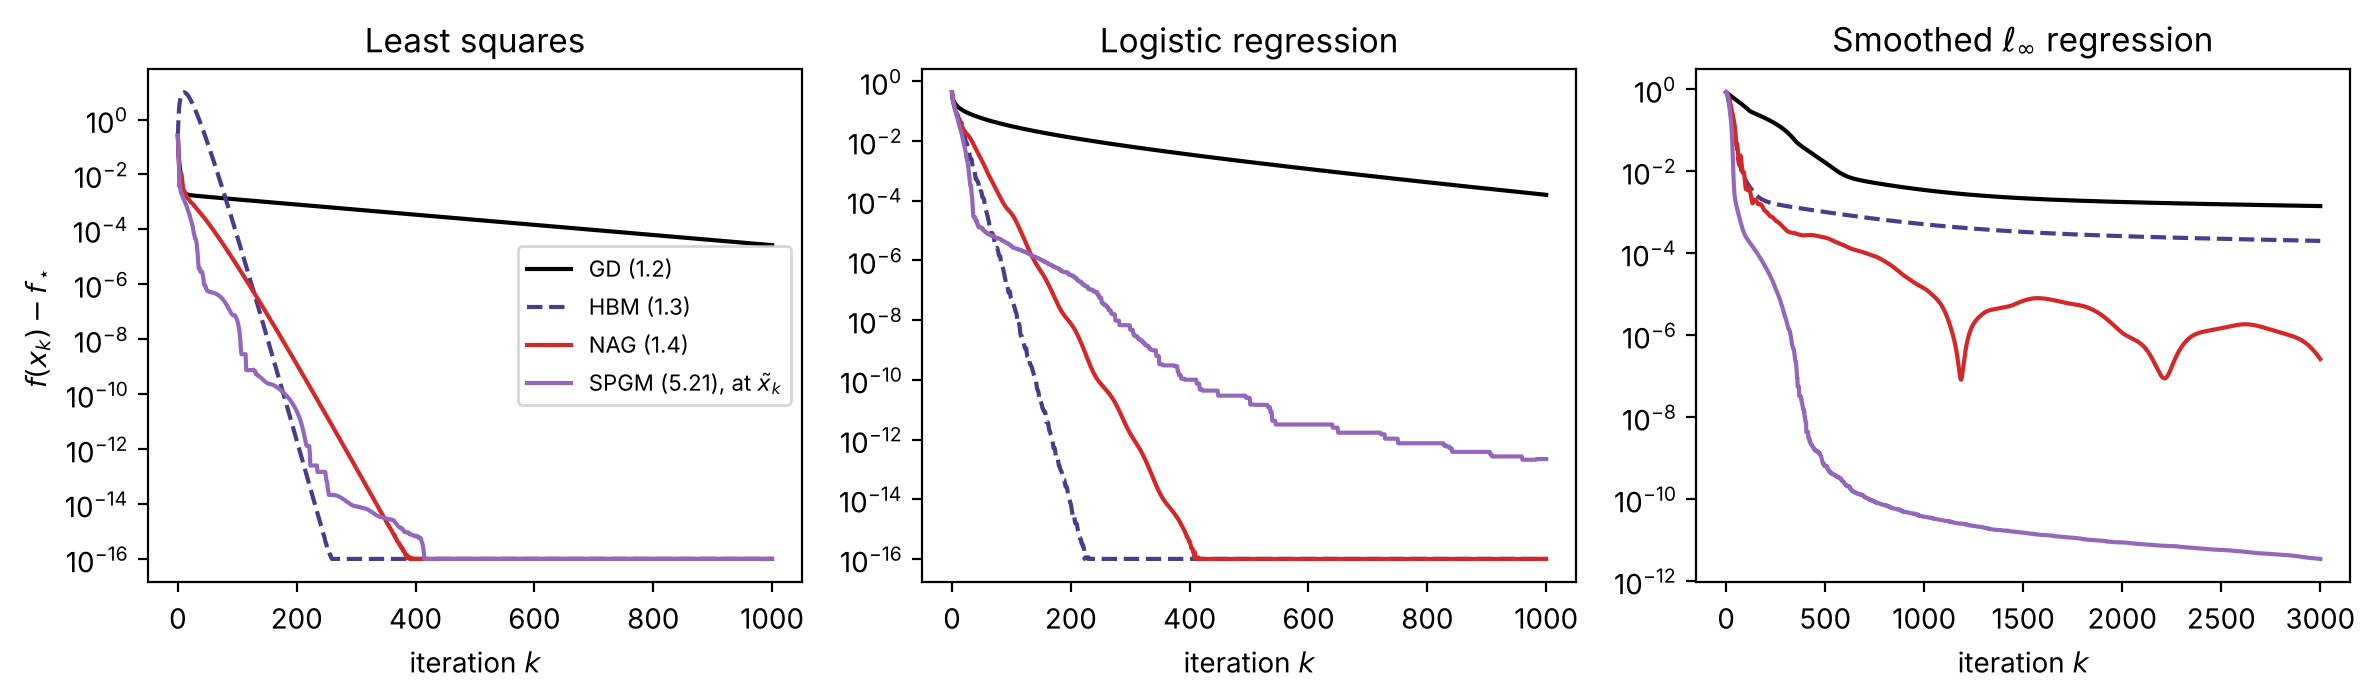

In [9]:
panels = {
    "Least squares": gaps_ls,
    "Logistic regression": gaps_logistic,
    r"Smoothed $\ell_\infty$ regression": gaps_linf,
}
styles = {
    "GD": dict(color="black", label="GD (1.2)"),
    "HBM": dict(color="darkslateblue", linestyle="--", label="HBM (1.3)"),
    "NAG": dict(color="tab:red", label="NAG (1.4)"),
    "SPGM": dict(color="tab:purple", label=r"SPGM (5.21), at $\tilde x_k$"),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (title, gaps) in zip(axes, panels.items()):
    for name, gap in gaps.items():
        ax.semilogy(np.maximum(gap, 1e-16), **styles[name])
    ax.set_title(title)
    ax.set_xlabel("iteration $k$")
axes[0].set_ylabel(r"$f(x_k) - f_\star$")
axes[0].legend(fontsize=8)
fig.tight_layout()
# fig.savefig("fig_section5_experiments.pdf")
plt.show()

## Save into .dat

In [10]:
import os

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

files = {
    "section5_least_squares_diabetes": gaps_ls,
    "section5_logistic_sonar": gaps_logistic,
    "section5_logsumexp_diabetes": gaps_linf,
}
columns = {"GD": "gd_f", "HBM": "hbm_f", "NAG": "nag_f", "SPGM": "spgm_f"}

for name, gaps in files.items():
    k = np.arange(len(gaps["GD"]))
    header = " ".join(["k"] + [columns[method] for method in gaps])
    fmt = ["%d"] + ["%.6e"] * len(gaps)
    table = np.column_stack([k] + [np.maximum(gap, 1e-16) for gap in gaps.values()])
    np.savetxt(f"{DATA_DIR}/{name}.dat", table, header=header, fmt=fmt, comments="")

    # thin copy: every iteration up to k = 50, then about 300 points, and the last one
    step = max(1, len(k) // 300)
    keep = (k <= 50) | (k % step == 0) | (k == k[-1])
    np.savetxt(f"{DATA_DIR}/{name}_thin.dat", table[keep], header=header, fmt=fmt, comments="")
    print(f"{DATA_DIR}/{name}.dat: {len(k)} rows, thin copy: {keep.sum()} rows")

data/section5_least_squares_diabetes.dat: 1001 rows, thin copy: 369 rows
data/section5_logistic_sonar.dat: 1001 rows, thin copy: 369 rows
data/section5_logsumexp_diabetes.dat: 3001 rows, thin copy: 346 rows


## Comparison with OGM, ITEM, triple momentum with quadratic averaging, and the methods with memory of Section 4

This last part adds three methods of Section 5 and puts all the methods of `Section4_experiments.ipynb` and of this notebook on the same figure.

- **OGM** (Algorithm 5.1, (5.10)): Nesterov's method with twice larger steps on the aggregated sequence. It does not use $m$, so it runs on the three problems. The plot shows $f(x_k)-f_\star$ at the gradient steps $x_k$, for which $f(x_k)-f_\star\leq L\|x_0-x_\star\|^2/(2A_k)$ (Section 5.3.2), as for SPGM above. The output (5.11) of the method stopped after $k$ iterations carries the guarantee $L\|x_0-x_\star\|^2/(2(A_k+\tilde a_k))$ of (5.12); its values are computed too (printed below and saved in the `.dat` files, not plotted).
- **ITEM** (Algorithm 5.8, (5.28)–(5.29)). It needs $m>0$: problems (i) and (ii) only. The plot shows $f(z_k)-f_\star$ at its output $z_k$, for which (5.30) gives $f(z_k)-f_\star\leq\tfrac L2\|z_k-x_\star\|^2\leq L\|x_0-x_\star\|^2/(2(1+2qA_k))$.
- **TMM with quadratic averaging** (Algorithm 5.12, (5.37)–(5.38)): the triple momentum recursion in which the weight $\lambda_k$ of the new piece $C_k$ is selected from the observed information, starting from $w_0=C_0$. It needs $m>0$: problems (i) and (ii) only. The plot shows $f(z_k)-f_\star$. The first point $z_1=x_0-\tfrac12\big(\tfrac1m+\tfrac1L\big)\nabla f(x_0)$ is the center of the ball (3.17a), which is far from $x_0$ when $m\ll L$.
- **NAG with memory** (Algorithm 4.13) and **OQA with memory** (Section 4.5): the two methods of `Section4_experiments.ipynb`, with the same code and the same limited memory. OQA with memory needs $m>0$.
- GD, HBM, NAG and SPGM: the values computed above.

| | uses $m$ | adapts to the history | problems |
|---|---|---|---|
| GD, OGM | no | no | (i), (ii), (iii) |
| HBM, NAG | on (i) and (ii) | no | (i), (ii), (iii) |
| ITEM | yes | no | (i), (ii) |
| NAG with memory, SPGM | no | yes | (i), (ii), (iii) |
| OQA with memory, TMM with quadratic averaging | yes | yes | (i), (ii) |

**A certificate for TMM with quadratic averaging.** The manuscript does not state it, but the method localizes the minimizer: as $w_k(x_\star)\leq f_\star\leq D_{k-1}(x_\star)$ and $w_k-D_{k-1}$ is a quadratic with curvature $\tfrac{2m}{1-q}$ minimized at $z_k$,
$$\|z_k-x_\star\|^2\leq R_k^2=\|z_k-z_0\|^2-\tfrac{1-q}{m}\big((1-\lambda_{k-1})\,e_0+\lambda_{k-1}\,e_1\big),$$
with $e_0$ and $e_1$ from (5.38) at iteration $k-1$, and $\lambda_{k-1}$ is the weight that minimizes this radius. It starts from $R_1=\tfrac12\big(\tfrac1m-\tfrac1L\big)\|\nabla f(x_0)\|$, the radius of the ball (3.17a), and the checks below compare it with the a priori rate $R_{k+1}^2\leq(1-\sqrt q)^2R_k^2$. The radius is a difference of quantities of order one, so it is meaningful down to about $10^{-12}$.

**Cost per iteration.** One gradient for OGM and ITEM, one gradient and one function value for TMM with quadratic averaging. The values at the plotted points are only computed for the plot.

### OGM, ITEM and TMM with quadratic averaging

In [11]:
def ogm(f, grad, x0, L, n_iter):
    # OGM (Algorithm 5.1). Returns f(x_0), ..., f(x_N) at the gradient steps, the values at the outputs (5.11)
    # of the method stopped after k = 0, ..., N iterations, and the weights A_k.
    x, z, A = x0.copy(), x0.copy(), 0.0
    values, outputs, weights = [f(x)], [f(x)], [A]
    for k in range(n_iter):
        a = 1 + np.sqrt(1 + 2 * A)
        A_next = A + a
        y = A / A_next * x + a / A_next * z
        g = grad(y)
        x = y - g / L
        z = z - a / L * g
        A = A_next
        a_last = (1 + np.sqrt(1 + 4 * A)) / 2                            # last increment, for the output (5.11)
        values.append(f(x))
        outputs.append(f(A / (A + a_last) * x + a_last / (A + a_last) * z))
        weights.append(A)
    return np.array(values), np.array(outputs), np.array(weights)


def item(f, grad, x0, L, m, n_iter):
    # ITEM (Algorithm 5.8). Returns f(z_0), ..., f(z_N), the points z_k and the weights A_k.
    q = m / L
    x, z, A = x0.copy(), x0.copy(), 0.0
    values, points, weights = [f(z)], [z.copy()], [A]
    for k in range(n_iter):
        a = (1 + q * (3 - q) * A + np.sqrt((1 + 2 * A) * (1 + 2 * q * A))) / (1 - q) ** 2    # increment (5.29)
        A_next = A + a
        tau = 1 - A / ((1 - q) * A_next)
        delta = (a + q * A_next) / (1 + 2 * q * A_next)
        y = (1 - tau) * x + tau * z
        g = grad(y)
        x = y - g / L
        z = z + q * delta * (y - z) - delta / L * g
        A = A_next
        values.append(f(z))
        points.append(z.copy())
        weights.append(A)
    return np.array(values), np.array(points), np.array(weights)


def tmm_qa(f, grad, x0, L, m, n_iter):
    # Triple momentum with quadratic averaging (Algorithm 5.12). The aggregate w_k is a quadratic with curvature m/(1-q),
    # stored through w_k(z_0) and grad w_k(z_0). Returns f(z_0), ..., f(z_N), the points z_k and the certified squared radii R_k^2.
    q = m / L
    s, c = np.sqrt(q), m / (1 - q)                                       # c: curvature of the pieces C_k and -D_k
    z0 = x0.copy()
    x, z = x0.copy(), x0.copy()
    values, points, radii = [f(z)], [z.copy()], [np.inf]
    for k in range(n_iter):
        y = x + 2 * s / (1 + s) * (z - x)
        g, f_y = grad(y), f(y)
        x = y - g / L
        r = c / 2 * (z0 - x) @ (z0 - x)
        C, grad_C = f_y + g @ (z0 - y) + g @ g / (2 * L) + r, g + c * (z0 - x)    # C_k (5.32) and its gradient at z_0
        D, grad_D = f_y - g @ g / (2 * L) - r, -c * (z0 - x)                      # D_k (5.32) and its gradient at z_0
        if k == 0:
            w, grad_w = C, grad_C                                        # w_0 = C_0
        e0, g0, e1, g1 = w - D, grad_w - grad_D, C - D, grad_C - grad_D  # (5.38)
        dg = g1 - g0
        if dg @ dg > 0:
            lam = np.clip((2 * c * (e1 - e0) - g0 @ dg) / (dg @ dg), 0, 1)
        else:                                                            # w_k and C_k differ by a constant (always the case for k = 0)
            lam = 1.0 if e1 >= e0 else 0.0
        w, grad_w = (1 - lam) * w + lam * C, (1 - lam) * grad_w + lam * grad_C    # w_{k+1}
        z = z0 - ((1 - lam) * g0 + lam * g1) / (2 * c)
        values.append(f(z))
        points.append(z.copy())
        radii.append((z - z0) @ (z - z0) - ((1 - lam) * e0 + lam * e1) / c)
    return np.array(values), np.array(points), np.array(radii)


def check(label, quantity, bound, k=100, slack=1e-15):
    # a quantity indexed by k = 0, ..., N against a bound indexed by k = 1, ..., N
    valid = np.all(quantity[1:] <= bound * (1 + 1e-9) + slack)
    print(f"  {label}: at k = {k}, {quantity[k]:.1e} <= {bound[k - 1]:.1e};  valid for all k: {valid}")

### The two methods with memory of Section 4

Same code as in `Section4_experiments.ipynb`. They use the functions `simplex_qp` and `largest_weight` defined above for SPGM.

In [12]:
def nag_memory(f, grad, x0, L, n_iter, memory=10):
    # NAG with memory (Algorithm 4.13). Affine pieces l_i stored as (l_i(x_0), grad f(y_i)); column 0 is the aggregate piece.
    x, z, A = x0.copy(), x0.copy(), 0.0
    c, G = np.zeros(0), np.zeros((len(x0), 0))
    values, weights = [f(x)], [A]
    for k in range(n_iter):
        a = (1 + np.sqrt(4 * A + 1)) / 2
        A_next = A + a                                                   # a priori weight
        y = A / A_next * x + a / A_next * z
        g, f_y = grad(y), f(y)
        x = y - g / L
        f_x = f(x)
        c, G = np.append(c, f_y + g @ (x0 - y)), np.column_stack([G, g])  # new piece l_k
        lam_prior = np.zeros(len(c))
        lam_prior[0] += A / A_next
        lam_prior[-1] += a / A_next
        A, lam = largest_weight(c - f_x, G, L, lam_prior)
        if not A >= A_next:                                              # floating-point safeguard
            A, lam = A_next, lam_prior
        z = x0 - A / L * G @ lam
        keep = slice(max(1, len(c) - memory), len(c))                    # last pieces (column 0 is the aggregate)
        c, G = np.append(c @ lam, c[keep]), np.column_stack([G @ lam, G[:, keep]])
        values.append(f_x)
        weights.append(A)
    return np.array(values), np.array(weights)


def oqa_memory(f, grad, x0, L, m, n_iter, memory=10):
    # OQA with memory (Section 4.5). Pieces l_i = c_i + m/2 ||. - w_i||^2 stored as (c_i, w_i); column 0 is the aggregate piece.
    s = np.sqrt(m / L)
    g = grad(x0)                                                         # initial piece at x_0, weight 1
    c, W = np.array([f(x0) - g @ g / (2 * m)]), (x0 - g / m)[:, None]
    x, z = x0.copy(), W[:, 0]
    Psi_0 = g @ g / (2 * m)
    values, weights = [f(x)], [1.0]
    for k in range(n_iter):
        y = x + s / (1 + s) * (z - x)
        g, f_y = grad(y), f(y)
        x = y - g / L
        c, W = np.append(c, f_y - g @ g / (2 * m)), np.column_stack([W, y - g / m])   # new piece l_k
        Wc = W - W[:, -1:]                                               # centered at the newest w_i
        b = c + m / 2 * np.sum(Wc ** 2, axis=0)
        value = lambda l: b @ l - m / 2 * np.sum((Wc @ l) ** 2)          # minimal value of sum_i l_i lam_i
        lam_prior = np.zeros(len(c))
        lam_prior[0] += 1 - s                                            # averaging (4.4) with tau_k = sqrt(q) 
        lam_prior[-1] += s
        lam = simplex_qp(b, Wc, m, lam_prior)
        if value(lam) < value(lam_prior):
            lam = lam_prior
        v, z = value(lam), W[:, -1] + Wc @ lam
        f_x = f(x)                                                       # only for the bookkeeping of the weight
        values.append(f_x)
        weights.append(Psi_0 / (f_x - v) if f_x > v else np.inf)
        keep = slice(max(1, len(c) - memory), len(c))
        c, W = np.append(v, c[keep]), np.column_stack([z, W[:, keep]])
    return np.array(values), np.array(weights)


def nesterov_weights(n_iter):
    # a priori weights of Nesterov's method, a_k^2 = A_{k+1}
    A = [0.0]
    for k in range(n_iter):
        A.append(A[-1] + (1 + np.sqrt(4 * A[-1] + 1)) / 2)
    return np.array(A)

### Runs

For each problem: the realized weights of the methods with memory against the a priori ones, as in `Section4_experiments.ipynb`, and the guarantees of OGM, ITEM and TMM with quadratic averaging against the observed quantities.

In [13]:
def run_comparison(problem, gaps_above, k=100):
    # All the methods on one problem; gaps_above contains GD, HBM, NAG and SPGM, computed above.
    f, grad, L, m, x_star, f_star, N = (problem[key] for key in ("f", "grad", "L", "m", "x_star", "f_star", "N"))
    x0 = np.zeros(len(x_star))
    R2 = np.sum((x0 - x_star) ** 2)
    gaps = {name: gaps_above[name] for name in ("GD", "HBM", "NAG")}

    values, weights = nag_memory(f, grad, x0, L, n_iter=N)
    gaps["NAG-mem"] = values - f_star
    report("NAG with memory", gaps["NAG-mem"], weights, nesterov_weights(N), L * R2 / 2, k, point="x_k")
    if m > 0:
        values, weights = oqa_memory(f, grad, x0, L, m, n_iter=N)
        gaps["OQA-mem"] = values - f_star
        Psi_0 = grad(x0) @ grad(x0) / (2 * m)
        report("OQA with memory", gaps["OQA-mem"], weights, (1 - np.sqrt(m / L)) ** -np.arange(N + 1), Psi_0, k, point="x_k")

    values, outputs, A = ogm(f, grad, x0, L, n_iter=N)
    gaps["OGM"], gaps["OGM-out"] = values - f_star, outputs - f_star
    a_last = (1 + np.sqrt(1 + 4 * A[1:])) / 2
    check("OGM, f(x_k) - f_star and L R^2/(2 A_k)", gaps["OGM"], L * R2 / (2 * A[1:]), k)
    check("OGM, output (5.11) and the bound (5.12)", gaps["OGM-out"], L * R2 / (2 * (A[1:] + a_last)), k)

    if m > 0:
        q = m / L
        values, points, A = item(f, grad, x0, L, m, n_iter=N)
        gaps["ITEM"] = values - f_star
        distances = np.sum((points - x_star) ** 2, axis=1)
        check("ITEM, |z_k - x_star|^2 and the bound (5.30)", distances, R2 / (1 + 2 * q * A[1:]), k)
        check("ITEM, f(z_k) - f_star and L/2 times this bound", gaps["ITEM"], L * R2 / (2 * (1 + 2 * q * A[1:])), k)

        values, points, radii = tmm_qa(f, grad, x0, L, m, n_iter=N)
        gaps["TMM-QA"] = values - f_star
        distances = np.sum((points - x_star) ** 2, axis=1)
        a_priori = (1 - np.sqrt(q)) ** (2 * np.arange(N)) * radii[1]
        check("TMM with quadratic averaging, |z_k - x_star|^2 and the certified R_k^2", distances, radii[1:], k, slack=1e-12)
        check("TMM with quadratic averaging, R_k^2 and the a priori (1 - sqrt q)^(2(k-1)) R_1^2", radii, a_priori, k, slack=1e-12)
        print(f"  TMM with quadratic averaging, first point: f(z_1) - f_star = {gaps['TMM-QA'][1]:.1e}, against f(x_0) - f_star = {gaps['TMM-QA'][0]:.1e}")

    gaps["SPGM"] = gaps_above["SPGM"]
    return gaps


print("(i) Least squares")
comparison_ls = run_comparison(problem_ls, gaps_ls)
print("(ii) Logistic regression")
comparison_logistic = run_comparison(problem_logistic, gaps_logistic)
print("(iii) Smoothed l_infinity regression")
comparison_linf = run_comparison(problem_linf, gaps_linf, k=1000)

(i) Least squares
  NAG with memory: at k = 100, weight 3.50e+05 (a priori 2.65e+03), bound 4.2e-06 >= f(x_k) - f_star = 9.2e-07;  bound valid for all k: True
  OQA with memory: at k = 100, weight 5.69e+08 (a priori 1.12e+02), bound 1.5e-07 >= f(x_k) - f_star = 1.5e-07;  bound valid for all k: True
  OGM, f(x_k) - f_star and L R^2/(2 A_k): at k = 100, 1.7e-06 <= 2.7e-04;  valid for all k: True
  OGM, output (5.11) and the bound (5.12): at k = 100, 3.0e-05 <= 2.7e-04;  valid for all k: True
  ITEM, |z_k - x_star|^2 and the bound (5.30): at k = 100, 1.4e-04 <= 1.9e-04;  valid for all k: True
  ITEM, f(z_k) - f_star and L/2 times this bound: at k = 100, 4.2e-05 <= 3.9e-04;  valid for all k: True
  TMM with quadratic averaging, |z_k - x_star|^2 and the certified R_k^2: at k = 100, 9.6e-06 <= 9.6e-06;  valid for all k: True
  TMM with quadratic averaging, R_k^2 and the a priori (1 - sqrt q)^(2(k-1)) R_1^2: at k = 100, 9.6e-06 <= 4.3e-01;  valid for all k: True
  TMM with quadratic averaging

### Iterations to a given accuracy

Number of iterations after which the gap stays below $10^{-6}$ and $10^{-10}$ (a dash when this does not happen within the run). The rows are the plotted curves, plus the output (5.11) of OGM.

In [14]:
names = {
    "GD": "GD", "HBM": "HBM", "NAG": "NAG", "NAG-mem": "NAG with memory", "OQA-mem": "OQA with memory",
    "OGM": "OGM, at x_k", "OGM-out": "OGM, output (5.11)", "ITEM": "ITEM, at z_k",
    "TMM-QA": "TMM with quad. averaging, at z_k", "SPGM": "SPGM, at x~_k",
}
comparisons = {"(i)": comparison_ls, "(ii)": comparison_logistic, "(iii)": comparison_linf}


def stays_below(gap, tol):
    # first iteration after which the gap stays below tol
    above = np.nonzero(gap > tol)[0]
    k = above[-1] + 1 if len(above) else 0
    return str(k) if k < len(gap) else "-"


table = pd.DataFrame({
    (problem, f"{tol:.0e}"): {names[method]: stays_below(gaps[method], tol) if method in gaps else "" for method in names}
    for problem, gaps in comparisons.items() for tol in (1e-6, 1e-10)
})
print(table.to_string())

                                   (i)        (ii)       (iii)      
                                 1e-06 1e-10 1e-06 1e-10 1e-06 1e-10
GD                                   -     -     -     -     -     -
HBM                                124   178    83   142     -     -
NAG                                120   230   139   246  2843     -
NAG with memory                     96   714   281     -   451     -
OQA with memory                     80   178    87   174            
OGM, at x_k                        189     -   373     -  2014     -
OGM, output (5.11)                 560     -   372     -  2014     -
ITEM, at z_k                       140   237    96   183            
TMM with quad. averaging, at z_k    75   164    91   184            
SPGM, at x~_k                       44   181   153   412   326   721


### Figure

Same conventions as above. The legend gives the point at which a method is evaluated when it is not $x_k$.

- **Fixed coefficients, without $m$.** On (iii), where both ignore $m$, OGM needs about $\sqrt2$ fewer iterations than NAG to stay below $10^{-6}$ (see the table), in line with the factor two between their guarantees. On (i) and (ii), OGM does not use $m$ and falls behind NAG after about a hundred iterations. On (i), $f(x_k)$ oscillates along OGM, and the values at the outputs (5.11) follow the upper envelope of these oscillations (column `ogm_out_f` of the `.dat` files); on the two other problems, the two values are nearly the same.
- **Fixed coefficients, with $m$.** ITEM is close to NAG on (i) and ahead of it on (ii).
- **Adapting to the history.** SPGM is far ahead of OGM on the three problems, and it is the only method that reaches $10^{-10}$ on (iii). TMM with quadratic averaging starts from a very large value, since $z_1$ is the center of a ball of radius $\tfrac12\big(\tfrac1m-\tfrac1L\big)\|\nabla f(x_0)\|$, and then catches up: it ends ahead of ITEM on (i) and on par with it on (ii), close to OQA with memory in both cases. Its certified radius is far below the a priori one.

The weights of TMM with quadratic averaging are ratios of differences that shrink along the iterations. After convergence these differences are below machine precision, which explains the small jumps of its curve at the level $10^{-15}$. As above, the details of the curves of the methods with memory in the last decades are sensitive to rounding.

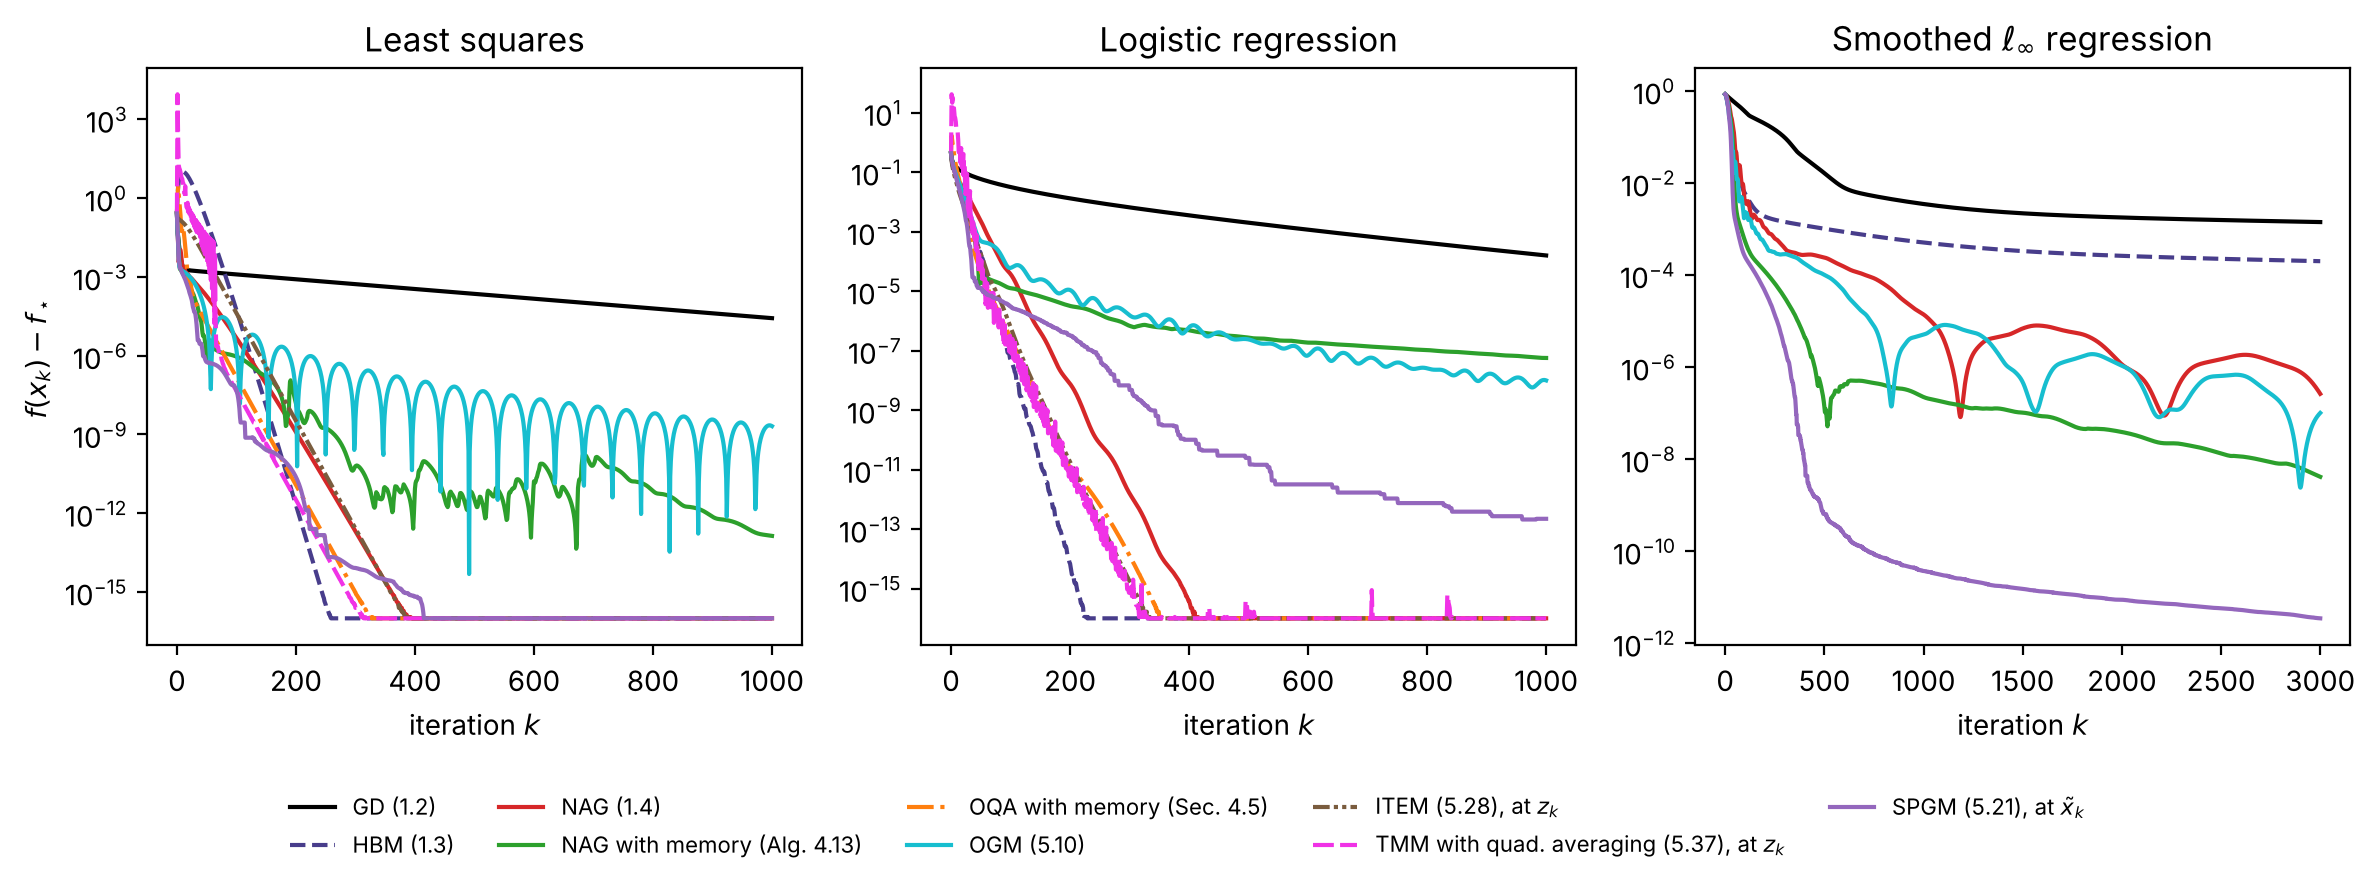

In [15]:
panels = {
    "Least squares": comparison_ls,
    "Logistic regression": comparison_logistic,
    r"Smoothed $\ell_\infty$ regression": comparison_linf,
}
styles = {
    "GD": dict(color="black", label="GD (1.2)"),
    "HBM": dict(color="darkslateblue", linestyle="--", label="HBM (1.3)"),
    "NAG": dict(color="tab:red", label="NAG (1.4)"),
    "NAG-mem": dict(color="tab:green", label="NAG with memory (Alg. 4.13)"),
    "OQA-mem": dict(color="tab:orange", linestyle="-.", label="OQA with memory (Sec. 4.5)"),
    "OGM": dict(color="tab:cyan", label="OGM (5.10)"),
    "ITEM": dict(color="#7a5c3e", linestyle=(0, (4, 1, 1, 1, 1, 1)), label=r"ITEM (5.28), at $z_k$"),
    "TMM-QA": dict(color="#f032e6", linestyle=(0, (5, 1.5)), label=r"TMM with quad. averaging (5.37), at $z_k$"),
    "SPGM": dict(color="tab:purple", label=r"SPGM (5.21), at $\tilde x_k$"),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4.4))
for ax, (title, gaps) in zip(axes, panels.items()):
    for name, style in styles.items():
        if name in gaps:
            ax.semilogy(np.maximum(gaps[name], 1e-16), **style)
    ax.set_title(title)
    ax.set_xlabel("iteration $k$")
axes[0].set_ylabel(r"$f(x_k) - f_\star$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5, fontsize=8, frameon=False)
fig.tight_layout(rect=(0, 0.11, 1, 1))
# fig.savefig("fig_section5_comparison.pdf")
plt.show()

### Save into .dat

One file per problem with all the curves of the last figure, and the column `ogm_out_f` for the output (5.11) of OGM.

In [16]:
files = {
    "section5_comparison_least_squares_diabetes": comparison_ls,
    "section5_comparison_logistic_sonar": comparison_logistic,
    "section5_comparison_logsumexp_diabetes": comparison_linf,
}
columns = {"GD": "gd_f", "HBM": "hbm_f", "NAG": "nag_f", "NAG-mem": "nagmem_f", "OQA-mem": "oqamem_f",
           "OGM": "ogm_f", "OGM-out": "ogm_out_f", "ITEM": "item_f", "TMM-QA": "tmmqa_f", "SPGM": "spgm_f"}

for name, gaps in files.items():
    k = np.arange(len(gaps["GD"]))
    header = " ".join(["k"] + [columns[method] for method in gaps])
    fmt = ["%d"] + ["%.6e"] * len(gaps)
    table = np.column_stack([k] + [np.maximum(gap, 1e-16) for gap in gaps.values()])
    np.savetxt(f"{DATA_DIR}/{name}.dat", table, header=header, fmt=fmt, comments="")

    # thin copy: every iteration up to k = 50, then about 300 points, and the last one
    step = max(1, len(k) // 300)
    keep = (k <= 50) | (k % step == 0) | (k == k[-1])
    np.savetxt(f"{DATA_DIR}/{name}_thin.dat", table[keep], header=header, fmt=fmt, comments="")
    print(f"{DATA_DIR}/{name}.dat: {len(k)} rows, columns {header}; thin copy: {keep.sum()} rows")

data/section5_comparison_least_squares_diabetes.dat: 1001 rows, columns k gd_f hbm_f nag_f nagmem_f oqamem_f ogm_f ogm_out_f item_f tmmqa_f spgm_f; thin copy: 369 rows
data/section5_comparison_logistic_sonar.dat: 1001 rows, columns k gd_f hbm_f nag_f nagmem_f oqamem_f ogm_f ogm_out_f item_f tmmqa_f spgm_f; thin copy: 369 rows
data/section5_comparison_logsumexp_diabetes.dat: 3001 rows, columns k gd_f hbm_f nag_f nagmem_f ogm_f ogm_out_f spgm_f; thin copy: 346 rows
